# Лабораторная работа №4. Байесовская сеть

**Тема:** характеристики животных и исходы их пребывания в приюте Austin Animal Center.

**Цель работы:** самостоятельно предложить структуру байесовской сети, оценить условные вероятности по данным и исследовать, как дополнительная информация о животном меняет распределение возможных исходов.

## Данные

Используем открытый датасет **Austin Animal Center Outcomes** за период с 1 октября 2013 года по 5 мая 2025 года. Он содержит записи об исходах пребывания животных в муниципальном приюте города Остин, США.

Источник: [каталог открытых данных Data.gov](https://catalog.data.gov/dataset/austin-animal-center-outcomes-10-01-2013-to-05-05-2025).

Один объект исследования — запись об исходе завершённого пребывания животного в приюте. Один и тот же питомец может попадать в приют неоднократно, поэтому запись не обязательно соответствует уникальному животному.

Рассмотрим тип животного, возраст, пол, породу, окрас и исход пребывания. Среди исходов — передача в новую семью (`Adoption`), возвращение владельцу (`Return to Owner`) и передача другой организации (`Transfer`). Окончательный набор переменных и их состояний выберем после изучения таблицы.

## Вопросы к вероятностной модели

1. Как меняется вероятность передачи в новую семью, если известна возрастная группа животного?
2. Как меняется вероятность возвращения владельцу, если известно, что животное — кошка или собака?
3. Как меняется вероятность передачи в новую семью, если одновременно известны тип животного, его возрастная группа и пол?

Для каждого вопроса сравним вероятность без дополнительных сведений с условной вероятностью при известных значениях признаков. Затем последовательно добавим сведения об одном выбранном профиле животного и исследуем изменение распределения исходов.

Сеть будет описывать зависимости в исторических данных. Причинный смысл связей и ограничения интерпретации обсудим отдельно.


## 1. Подготовка

Подключим библиотеки для работы с данными и графиками. Зададим `SEED = 42` для воспроизводимости и общие настройки отображения.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from IPython.display import display
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.inference import VariableElimination

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

D:\5 сем лабы\машинное обучение\ml_course_mai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


D:\5 сем лабы\машинное обучение\ml_course_mai\.venv\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


## 2. Загрузка данных

Загрузим Austin Animal Center Outcomes из сохранённого CSV. Посмотрим размер таблицы, первые строки, типы столбцов, пропуски и число полных дубликатов.

In [2]:
data = pd.read_csv("data/austin_animal_center_outcomes.csv")

print("Размер таблицы:", data.shape)
print("Полных дубликатов:", data.duplicated().sum())

display(data.head())

display(pd.DataFrame({
    "Тип": data.dtypes.astype(str),
    "Пропуски": data.isna().sum(),
    "Пропуски, %": (data.isna().mean() * 100).round(2),
}))

Размер таблицы: (173775, 12)


Полных дубликатов: 26


,Animal ID,Date of Birth,Name,DateTime,MonthYear,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color
0,A668305,2012-12-01,NaN,2013-12-02T00:00:00-05:00,12-2013,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Brown/Yellow
1,A673335,2012-02-22,NaN,2014-02-22T00:00:00-05:00,02-2014,Euthanasia,Suffering,Other,Unknown,2 years,Raccoon,Black/Gray
2,A675999,2013-04-03,NaN,2014-04-07T00:00:00-05:00,04-2014,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Green
3,A679066,2014-04-16,NaN,2014-05-16T00:00:00-05:00,05-2014,NaN,NaN,Other,Unknown,4 weeks,Rabbit Sh,Brown
4,A680855,2014-05-25,NaN,2014-06-10T00:00:00-05:00,06-2014,Transfer,Partner,Bird,Unknown,2 weeks,Duck,Yellow/Black


,Тип,Пропуски,"Пропуски, %"
Animal ID,str,0,0.00
Date of Birth,str,0,0.00
Name,str,49784,28.65
DateTime,str,0,0.00
MonthYear,str,0,0.00
Outcome Type,str,46,0.03
Outcome Subtype,str,94115,54.16
Animal Type,str,0,0.00
Sex upon Outcome,str,1,0.00
Age upon Outcome,str,9,0.01


## 3. Типы животных и исходы

Посмотрим количество и долю записей для каждого типа животного и исхода пребывания. Сравним распределения на графиках, чтобы оценить представленность категорий и выбрать рабочую выборку.

,Количество,"Доля, %"
Animal Type,,
Dog,94505,54.38
Cat,69399,39.94
Other,8960,5.16
Bird,877,0.50
Livestock,34,0.02


,Количество,"Доля, %"
Outcome Type,,
Adoption,84598,48.68
Transfer,48689,28.02
Return to Owner,25691,14.78
Euthanasia,10833,6.23
Died,1672,0.96
Rto-Adopt,1241,0.71
Disposal,877,0.50
Missing,92,0.05
Не указан,46,0.03


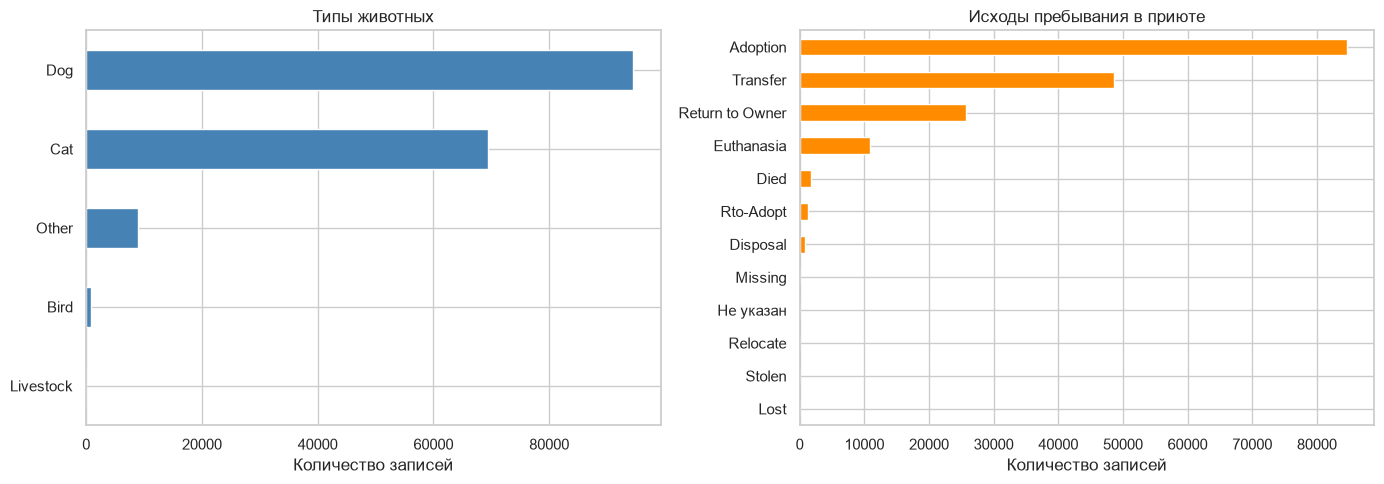

In [3]:
animal_stats = data["Animal Type"].value_counts().to_frame("Количество")
animal_stats["Доля, %"] = (animal_stats["Количество"] / len(data) * 100).round(2)

outcome_stats = data["Outcome Type"].fillna("Не указан").value_counts().to_frame("Количество")
outcome_stats["Доля, %"] = (outcome_stats["Количество"] / len(data) * 100).round(2)

display(animal_stats)
display(outcome_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

animal_stats["Количество"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Типы животных", xlabel="Количество записей", ylabel="")

outcome_stats["Количество"].sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set(title="Исходы пребывания в приюте", xlabel="Количество записей", ylabel="")

plt.tight_layout()
plt.show()

## 4. Рабочая выборка

Оставим кошек и собак: вместе они составляют 94,32% записей. Удалим полные дубликаты и строки без указанного исхода. Повторяющиеся `Animal ID` сохраним, поскольку одно животное может попадать в приют несколько раз.

In [4]:
animals = data[data["Animal Type"].isin(["Cat", "Dog"])].copy()

print("Кошек и собак до очистки:", len(animals))
print("Полных дубликатов:", animals.duplicated().sum())
animals = animals.drop_duplicates()

print("Записей без исхода:", animals["Outcome Type"].isna().sum())
animals = animals.dropna(subset=["Outcome Type"]).reset_index(drop=True)

print("Размер рабочей таблицы:", animals.shape)
display(animals["Animal Type"].value_counts().to_frame("Количество"))

Кошек и собак до очистки: 163904


Полных дубликатов: 24


Записей без исхода: 39
Размер рабочей таблицы: (163841, 12)


,Количество
Animal Type,
Dog,94463
Cat,69378


## 5. Возраст и пол

Переведём возраст в дни, приближённо считая месяц равным 30 дням, а год — 365 дням. Отрицательные значения отметим как пропуски. Из `Sex upon Outcome`, содержащего пол и статус стерилизации, выделим пол; неизвестные значения сохраним как `Unknown`.

In [5]:
age_parts = animals["Age upon Outcome"].str.split(expand=True)
age_units = age_parts[1].str.rstrip("s")
days_per_unit = {"day": 1, "week": 7, "month": 30, "year": 365}

animals["AgeDays"] = pd.to_numeric(age_parts[0], errors="coerce") * age_units.map(days_per_unit)
negative_age = animals["AgeDays"] < 0
print("Отрицательных значений возраста:", negative_age.sum())
animals.loc[negative_age, "AgeDays"] = np.nan

animals["Sex"] = animals["Sex upon Outcome"].str.split().str[-1].fillna("Unknown")

print("Пропусков возраста после обработки:", animals["AgeDays"].isna().sum())
display(animals[["Age upon Outcome", "AgeDays", "Sex upon Outcome", "Sex"]].head())
display(animals["AgeDays"].describe().to_frame("Возраст, дни"))
display(animals["Sex"].value_counts().to_frame("Количество"))

Отрицательных значений возраста: 9


Пропусков возраста после обработки: 14


,Age upon Outcome,AgeDays,Sex upon Outcome,Sex
0,2 months,60.0,Spayed Female,Female
1,1 year,365.0,Intact Male,Male
2,8 months,240.0,Intact Male,Male
3,3 weeks,21.0,Intact Female,Female
4,3 weeks,21.0,Intact Female,Female


,"Возраст, дни"
count,163827.000000
mean,736.873873
std,1044.525416
min,0.000000
25%,60.000000
50%,365.000000
75%,730.000000
max,8760.000000


,Количество
Sex,
Male,81994
Female,76097
Unknown,5750


## 6. Возрастные группы

Разделим возраст на три группы: до 1 года, от 1 года до 7 лет и от 7 лет. Границы отделяют самых молодых животных и позволяют сравнить две группы более старшего возраста без большого числа состояний в сети. Это выбранная для анализа дискретизация. Левая граница включается: ровно 1 год относится ко второй группе, ровно 7 лет — к третьей. Пропуски сохраним в категории `Unknown`.

In [6]:
animals["AgeGroup"] = pd.cut(
    animals["AgeDays"],
    bins=[0, 365, 7 * 365, np.inf],
    labels=["До 1 года", "1–6 лет", "7 лет и старше"],
    right=False,
)
animals["AgeGroup"] = animals["AgeGroup"].cat.add_categories("Unknown").fillna("Unknown")

age_stats = animals["AgeGroup"].value_counts(sort=False).to_frame("Количество")
age_stats["Доля, %"] = (age_stats["Количество"] / len(animals) * 100).round(2)

display(age_stats)
display(pd.crosstab(animals["AgeGroup"], animals["Animal Type"]))

,Количество,"Доля, %"
AgeGroup,,
До 1 года,76247,46.54
1–6 лет,73338,44.76
7 лет и старше,14242,8.69
Unknown,14,0.01


Animal Type,Cat,Dog
AgeGroup,,
До 1 года,45627,30620
1–6 лет,19835,53503
7 лет и старше,3911,10331
Unknown,5,9


## 7. Группировка исходов

Сохраним три основных исхода: передачу в новую семью (`Adoption`), передачу другой организации (`Transfer`) и возвращение владельцу (`Return to Owner`). Остальные объединим в `Other`, чтобы уменьшить число состояний сети. Проверим размеры категорий и состав группы `Other`: она объединяет разные события, поэтому её вероятность будем интерпретировать как суммарную вероятность остальных исходов.

In [7]:
main_outcomes = ["Adoption", "Transfer", "Return to Owner"]
animals["Outcome"] = animals["Outcome Type"].where(
    animals["Outcome Type"].isin(main_outcomes), "Other"
)

outcome_group_stats = animals["Outcome"].value_counts().to_frame("Количество")
outcome_group_stats["Доля, %"] = (outcome_group_stats["Количество"] / len(animals) * 100).round(2)

display(outcome_group_stats)
display(animals.loc[animals["Outcome"] == "Other", "Outcome Type"].value_counts().to_frame("Количество в Other"))

,Количество,"Доля, %"
Outcome,,
Adoption,83245,50.81
Transfer,47262,28.85
Return to Owner,25554,15.60
Other,7780,4.75


,Количество в Other
Outcome Type,
Euthanasia,4777
Died,1407
Rto-Adopt,1236
Disposal,260
Missing,86
Relocate,8
Stolen,5
Lost,1


## 8. Данные для байесовской сети

Соберём таблицу `network_data` из четырёх переменных: типа животного, возрастной группы, пола и исхода. Проверим число состояний и пропуски. Одинаковые сочетания этих признаков сохраним: их частоты нужны для оценки вероятностей.

In [8]:
network_data = animals[["Animal Type", "AgeGroup", "Sex", "Outcome"]].rename(
    columns={"Animal Type": "AnimalType"}
).copy()

print("Размер таблицы для сети:", network_data.shape)
display(network_data.head())

display(pd.DataFrame({
    "Число состояний": network_data.nunique(),
    "Пропуски": network_data.isna().sum(),
}))

Размер таблицы для сети: (163841, 4)


,AnimalType,AgeGroup,Sex,Outcome
0,Dog,До 1 года,Female,Adoption
1,Dog,1–6 лет,Male,Transfer
2,Dog,До 1 года,Male,Transfer
3,Cat,До 1 года,Female,Transfer
4,Cat,До 1 года,Female,Transfer


,Число состояний,Пропуски
AnimalType,2,0
AgeGroup,4,0
Sex,3,0
Outcome,4,0


## 9. Структура байесовской сети

Зададим структуру вручную:

- `AnimalType → AgeGroup`: состав поступающих в приют кошек и собак может различаться по возрасту. Возрастную структуру моделируем условно по типу животного.
- `AnimalType → Outcome`: предполагаем, что сценарии передачи в семью, другую организацию и возвращения владельцу могут различаться для кошек и собак.
- `AgeGroup → Outcome`: предполагаем, что предпочтения новых владельцев и условия устройства животных могут различаться в зависимости от возраста.
- `Sex → Outcome`: допускаем различия исходов по зарегистрированному полу, связанные с составом животных и особенностями их устройства.

Направления к `Outcome` выбраны для оценки исхода по характеристикам животного. Сеть описывает завершённые пребывания: возраст известен на момент исхода. Стрелки сами по себе не доказывают причинность.

Упрощающее предположение этой структуры: `Sex` независим от `AnimalType` и `AgeGroup` до получения информации об исходе. В данных это может выполняться приближённо, особенно для категории `Unknown`. Проверим отсутствие циклов и нарисуем граф.

Граф является DAG: True


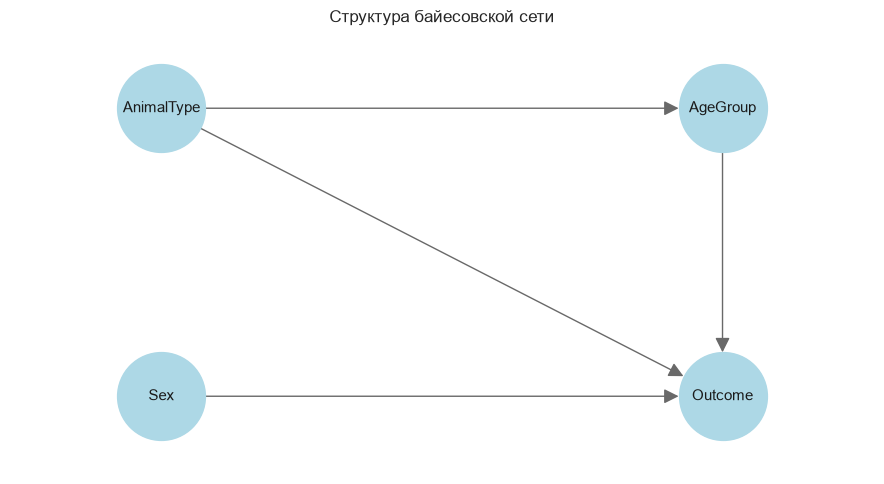

In [9]:
edges = [
    ("AnimalType", "AgeGroup"),
    ("AnimalType", "Outcome"),
    ("AgeGroup", "Outcome"),
    ("Sex", "Outcome"),
]
graph = nx.DiGraph(edges)

print("Граф является DAG:", nx.is_directed_acyclic_graph(graph))

positions = {
    "AnimalType": (0, 1),
    "AgeGroup": (2, 1),
    "Sex": (0, 0),
    "Outcome": (2, 0),
}

plt.figure(figsize=(9, 5))
nx.draw_networkx(
    graph, pos=positions, node_size=4000, node_color="lightblue",
    font_size=11, arrowsize=22, edge_color="dimgray",
)
plt.title("Структура байесовской сети")
plt.axis("off")
plt.margins(0.2)
plt.tight_layout()
plt.show()

## 10. Создание и обучение байесовской сети

Создадим модель с выбранной структурой и оценим таблицы вероятностей по `network_data`. Используем сглаживание Лапласа: к числу наблюдений каждого состояния при каждом сочетании родителей добавляем 1. Это особенно важно для редких сочетаний с `Unknown`.

Проверим согласованность таблиц и нормировку вероятностей. Посмотрим распределение `AnimalType` и таблицу `P(AgeGroup | AnimalType)`: в каждом её столбце вероятности возрастных групп суммируются до 1.

In [10]:
model = DiscreteBayesianNetwork(edges)
estimator = DiscreteBayesianEstimator(
    prior_type="dirichlet",
    pseudo_counts=1,
)
model.fit(network_data, estimator=estimator)

print("Модель корректна:", model.check_model())
print("Число таблиц вероятностей:", len(model.get_cpds()))

type_cpd = model.get_cpds("AnimalType")
display(pd.DataFrame(
    {"P(AnimalType)": type_cpd.values},
    index=type_cpd.state_names["AnimalType"],
).round(4))

age_cpd = model.get_cpds("AgeGroup")
age_table = pd.DataFrame(
    age_cpd.get_values(),
    index=age_cpd.state_names["AgeGroup"],
    columns=age_cpd.state_names["AnimalType"],
)
display(age_table.reindex(age_stats.index).round(4))

Модель корректна: True
Число таблиц вероятностей: 4


,P(AnimalType)
Cat,0.4234
Dog,0.5766


,Cat,Dog
AgeGroup,,
До 1 года,0.6576,0.3241
1–6 лет,0.2859,0.5664
7 лет и старше,0.0564,0.1094
Unknown,0.0001,0.0001


## 11. Проверка таблицы вероятностей исхода

Проверим, что оценённые вероятности исходов согласуются с частотами в данных. У `Outcome` три родителя, поэтому для выбора конкретного столбца его таблицы задаём тип животного, возраст и пол.

Для примера произвольно выберем `Female` и рассмотрим четыре сочетания типа и возраста. В каждой группе сравним частоты исходов с вероятностями модели; `N` — число записей в группе. Почти одинаковые значения ожидаемы: параметры рассчитаны по этим данным, а сглаживание при большом `N` влияет слабо. Вероятности при известном только возрасте получим на следующем этапе вероятностного вывода.

In [11]:
outcome_cpd = model.get_cpds("Outcome")
profiles = [
    ("Cat", "До 1 года"),
    ("Cat", "1–6 лет"),
    ("Dog", "До 1 года"),
    ("Dog", "1–6 лет"),
]

rows = []
for animal_type, age_group in profiles:
    group = network_data[
        (network_data["AnimalType"] == animal_type)
        & (network_data["AgeGroup"] == age_group)
        & (network_data["Sex"] == "Female")
    ]
    frequencies = group["Outcome"].value_counts(normalize=True)

    for outcome in outcome_cpd.state_names["Outcome"]:
        probability = outcome_cpd.get_value(
            Outcome=outcome, AnimalType=animal_type,
            AgeGroup=age_group, Sex="Female",
        )
        rows.append({
            "Тип": animal_type, "Возраст": age_group, "Исход": outcome,
            "N": len(group),
            "По данным, %": frequencies.get(outcome, 0) * 100,
            "Модель, %": probability * 100,
        })

cpd_comparison = pd.DataFrame(rows).set_index(["Тип", "Возраст", "Исход"])
display(cpd_comparison.round(2))

N  По данным, %  Модель, %
Тип Возраст   Исход                                          
Cat До 1 года Adoption         20633         62.77      62.77
              Other            20633          3.45       3.45
              Return to Owner  20633          0.91       0.92
              Transfer         20633         32.87      32.87
    1–6 лет   Adoption          9882         43.93      43.92
              Other             9882          5.53       5.53
              Return to Owner   9882          7.66       7.67
              Transfer          9882         42.89      42.88
Dog До 1 года Adoption         15348         64.94      64.93
              Other            15348          2.05       2.05
              Return to Owner  15348          7.87       7.88
              Transfer         15348         25.14      25.14
    1–6 лет   Adoption         23499         49.40      49.39
              Other            23499          3.51       3.51
              Return to Owner  23499         25.92      25.92
              Transfer         23499         21.17      21.17

## 12. Вероятность исхода при известном возрасте

Сравним рассчитанные сетью вероятности исходов в двух случаях: ничего о животном не известно и известно только, что ему меньше года. Получим `P(Outcome)` и `P(Outcome | AgeGroup = До 1 года)`. Тип животного и пол сеть учтёт через их возможные значения и вероятности. Разницу выразим в процентных пунктах.

In [12]:
inference = VariableElimination(model)

baseline = inference.query(variables=["Outcome"], show_progress=False)
young = inference.query(
    variables=["Outcome"],
    evidence={"AgeGroup": "До 1 года"},
    show_progress=False,
)

age_query_table = pd.DataFrame({
    "Без сведений, %": baseline.values * 100,
    "Возраст до года, %": young.values * 100,
    "Изменение, п.п.": (young.values - baseline.values) * 100,
}, index=baseline.state_names["Outcome"])

display(age_query_table.round(2))

,"Без сведений, %","Возраст до года, %","Изменение, п.п."
Adoption,51.01,60.56,9.55
Other,5.01,3.41,-1.60
Return to Owner,15.82,4.21,-11.61
Transfer,28.15,31.81,3.66


## 13. Вероятность исхода при известном типе животного

Сравним `P(Outcome)` с `P(Outcome | AnimalType = Cat)` и `P(Outcome | AnimalType = Dog)`. В каждом запросе известен только тип животного; возраст и пол сеть учитывает через их распределения. Особое внимание уделим вероятности возвращения владельцу — это второй вопрос, сформулированный в начале работы.

In [13]:
cat = inference.query(
    variables=["Outcome"],
    evidence={"AnimalType": "Cat"},
    show_progress=False,
)
dog = inference.query(
    variables=["Outcome"],
    evidence={"AnimalType": "Dog"},
    show_progress=False,
)

type_query_table = pd.DataFrame({
    "Без сведений, %": baseline.values * 100,
    "Кошка, %": cat.values * 100,
    "Собака, %": dog.values * 100,
}, index=baseline.state_names["Outcome"])

display(type_query_table.round(2))

,"Без сведений, %","Кошка, %","Собака, %"
Adoption,51.01,53.65,49.08
Other,5.01,5.63,4.56
Return to Owner,15.82,4.27,24.31
Transfer,28.15,36.45,22.06


## 14. Последовательное добавление сведений

Возьмём пример: собака младше года, самка. Будем последовательно сообщать сети тип животного, возраст и пол. На каждом шаге получим распределение исходов и проследим изменение вероятности передачи в семью. Последний шаг отвечает на третий вопрос работы — об исходе при одновременно известных трёх признаках.

В графе все три признака связаны с `Outcome`, а тип животного также связан с возрастом. Поэтому знание типа учитывает возрастную структуру собак; следующий факт уточняет возрастную группу, а последний — пол.

,Adoption,Other,Return to Owner,Transfer
Без сведений,51.01,5.01,15.82,28.15
Собака,49.08,4.56,24.31,22.06
"Собака, до года",61.34,2.52,8.95,27.19
"Собака, до года, самка",64.93,2.05,7.88,25.14


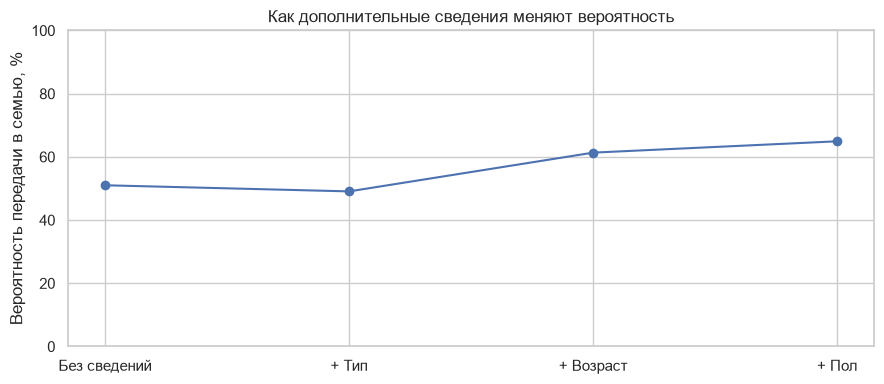

In [14]:
evidence_steps = [
    ("Без сведений", {}),
    ("Собака", {"AnimalType": "Dog"}),
    ("Собака, до года", {"AnimalType": "Dog", "AgeGroup": "До 1 года"}),
    ("Собака, до года, самка", {"AnimalType": "Dog", "AgeGroup": "До 1 года", "Sex": "Female"}),
]

distributions = []
for step, evidence in evidence_steps:
    result = inference.query(variables=["Outcome"], evidence=evidence, show_progress=False)
    distributions.append(pd.Series(
        result.values * 100, index=result.state_names["Outcome"], name=step
    ))

evidence_table = pd.DataFrame(distributions)
display(evidence_table.round(2))

plt.figure(figsize=(9, 4))
plt.plot(range(4), evidence_table["Adoption"], marker="o")
plt.xticks(range(4), ["Без сведений", "+ Тип", "+ Возраст", "+ Пол"])
plt.ylabel("Вероятность передачи в семью, %")
plt.title("Как дополнительные сведения меняют вероятность")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 15. Влияние структуры сети

Создадим отдельную сеть и удалим ребро `AgeGroup → Outcome`. Заново оценим вероятности на тех же данных с тем же сглаживанием. Повторим запрос для собаки младше года, самки, и сравним распределение исходов.

После удаления ребра таблица исхода имеет вид `P(Outcome | AnimalType, Sex)`. При известных типе животного и поле возраст больше не уточняет исход: мы явно исключили эту зависимость из модели.

In [15]:
reduced_model = DiscreteBayesianNetwork(edges)
reduced_model.remove_edge("AgeGroup", "Outcome")
reduced_model.fit(
    network_data,
    estimator=DiscreteBayesianEstimator(prior_type="dirichlet", pseudo_counts=1),
)
print("Изменённая модель корректна:", reduced_model.check_model())

reduced_inference = VariableElimination(reduced_model)
profile = {"AnimalType": "Dog", "AgeGroup": "До 1 года", "Sex": "Female"}

original_result = inference.query(
    variables=["Outcome"], evidence=profile, show_progress=False
)
reduced_result = reduced_inference.query(
    variables=["Outcome"], evidence=profile, show_progress=False
)

structure_comparison = pd.DataFrame({
    "Исходная сеть, %": original_result.values * 100,
    "Без ребра возраста, %": reduced_result.values * 100,
    "Изменение, п.п.": (reduced_result.values - original_result.values) * 100,
}, index=original_result.state_names["Outcome"])

display(structure_comparison.round(2))

Изменённая модель корректна: True


,"Исходная сеть, %","Без ребра возраста, %","Изменение, п.п."
Adoption,64.93,52.90,-12.03
Other,2.05,3.40,1.35
Return to Owner,7.88,21.46,13.58
Transfer,25.14,22.24,-2.90


## 16. Выводы и ограничения

Построена байесовская сеть для 163 841 записи о завершённых пребываниях кошек и собак в приюте. Структура задана вручную, таблицы вероятностей оценены по данным со сглаживанием Лапласа.

**Ответы на вопросы работы:**

1. Знание возраста до года повышает рассчитанную сетью вероятность передачи в семью с **51,01% до 60,56%**. Молодой возраст связан с большей долей этого исхода.
2. Вероятность возвращения владельцу составляет **15,82%** без дополнительных сведений, **4,27%** при известном типе `Cat` и **24,31%** при типе `Dog`. Тип животного заметно уточняет распределение исходов.
3. Для собаки младше года, самки, вероятность передачи в семью равна **64,93%**. Последовательное добавление сведений даёт **51,01% → 49,08% → 61,34% → 64,93%**. В этом порядке наибольшее изменение связано с уточнением возраста. Тип животного также меняет учитываемую сетью возрастную структуру через ребро `AnimalType → AgeGroup`.

**Влияние структуры.** После удаления `AgeGroup → Outcome` и повторной оценки параметров вероятность передачи в семью для того же животного снизилась с **64,93% до 52,90%**, на **12,03 процентного пункта**. При известных типе и поле изменённая сеть использует общую таблицу исходов для всех возрастов. Следовательно, результат зависит от принятых предположений о связях.

**Причинность и направления стрелок.** Построенная сеть описывает статистические зависимости; оснований считать её доказанной причинной моделью нет. Направления выбраны для удобного представления распределения исхода по характеристикам животного. По одним наблюдаемым данным направление связи часто нельзя определить однозначно: разные графы могут описывать одинаковые зависимости. Для причинной интерпретации нужны дополнительные предположения, сведения о механизмах или данные вмешательств. Удаление ребра в нашем эксперименте меняет предположение модели.

**Ограничения:**

- Выборка относится к одному приюту и завершённым пребываниям; один питомец может встречаться несколько раз.
- Возраст записан на момент исхода и приближённо переведён в дни. Границы возрастных групп выбраны вручную.
- Использованы четыре переменные; порода, здоровье, обстоятельства поступления и условия работы приюта не учитывались. Независимость пола от типа и возраста — упрощение выбранного графа.
- `Other` объединяет разные исходы. Сочетания с редкой категорией возраста `Unknown` имеют мало наблюдений; сглаживание даёт ненулевые оценки, но не устраняет недостаток данных.
